# Прогноз цены подержанного автомобиля

Данные: [Used Car Price Prediction Dataset](https://www.kaggle.com/datasets/taeefnajib/used-car-price-prediction-dataset), 4 009 объявлений. Цель предсказать цену в долларах

## Гипотезы, зафиксированные до экспериментов

1. Год выпуска положительно коррелирует с ценой: коэффициент Спирмена > 0
2. Пробег отрицательно коррелирует с ценой: коэффициент Спирмена < 0
3. Ridge с подобранной регуляризацией даст меньшую среднюю CV MAE, чем обычная линейная регрессия
4. Случайный лес даст меньшую среднюю CV MAE, чем одиночное дерево после подбора параметров обоих
5. Дерево глубины 15 покажет переобучение относительно глубины 5: MAE на обучении снизится, а на тесте вырастет
6. Категориальные признаки уменьшат среднюю CV MAE Ridge относительно модели только с годом и пробегом
7. Отбор 20 признаков методом SelectKBest даст Ridge CV MAE не более чем на 5% выше модели со всеми признаками

Для сравнения моделей используем MAE как основную метрику, а также RMSE и R². Разбиение train/test — 80/20, `random_state=42`; подбор — 3-кратная CV только на train

In [5]:
import os
os.environ["MPLCONFIGDIR"] = ".cache/matplotlib"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.feature_selection import SelectKBest, f_regression
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV, KFold, cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

df = pd.read_csv("used_cars.csv")
df["milage"] = pd.to_numeric(df["milage"].str.replace(r"[^0-9.]", "", regex=True), errors="coerce")
df["price"] = pd.to_numeric(df["price"].str.replace(r"[^0-9.]", "", regex=True), errors="coerce")
df = df.dropna(subset=["price"])
print("Размер:", df.shape)
display(df.head())
display(df.isna().sum().to_frame("пропуски"))

Размер: (4009, 12)


,brand,model,model_year,milage,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title,price
0,Ford,Utility Police Interceptor Base,2013,51000.0,E85 Flex Fuel,300.0HP 3.7L V6 Cylinder Engine Flex Fuel Capa...,6-Speed A/T,Black,Black,At least 1 accident or damage reported,Yes,10300
1,Hyundai,Palisade SEL,2021,34742.0,Gasoline,3.8L V6 24V GDI DOHC,8-Speed Automatic,Moonlight Cloud,Gray,At least 1 accident or damage reported,Yes,38005
2,Lexus,RX 350 RX 350,2022,22372.0,Gasoline,3.5 Liter DOHC,Automatic,Blue,Black,None reported,NaN,54598
3,INFINITI,Q50 Hybrid Sport,2015,88900.0,Hybrid,354.0HP 3.5L V6 Cylinder Engine Gas/Electric H...,7-Speed A/T,Black,Black,None reported,Yes,15500
4,Audi,Q3 45 S line Premium Plus,2021,9835.0,Gasoline,2.0L I4 16V GDI DOHC Turbo,8-Speed Automatic,Glacier White Metallic,Black,None reported,NaN,34999


,пропуски
brand,0
model,0
model_year,0
milage,0
fuel_type,170
engine,0
transmission,0
ext_col,0
int_col,0
accident,113


## EDA

Смотрим пропуски, распределения, связь числовых признаков с ценой и частоты категорий

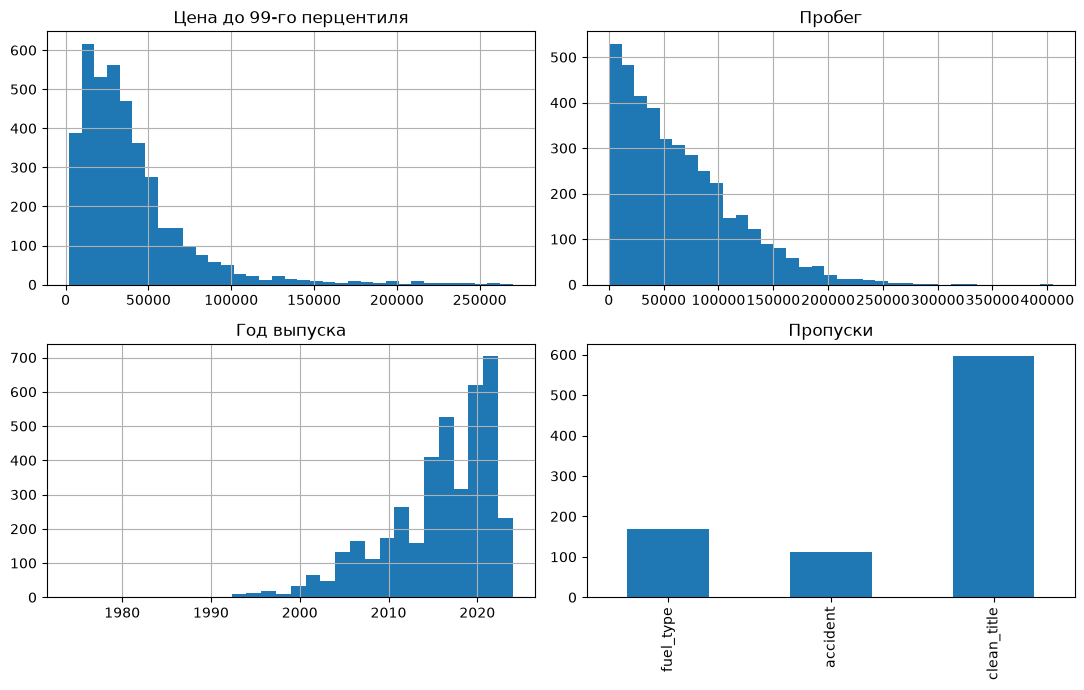

,model_year,milage,price
model_year,1.000000,-0.723843,0.697388
milage,-0.723843,1.000000,-0.755174
price,0.697388,-0.755174,1.000000


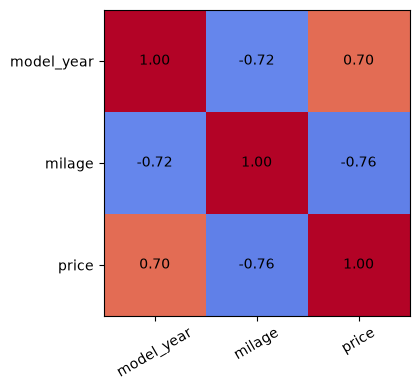

,price
count,4.009000e+03
mean,4.455319e+04
std,7.871064e+04
min,2.000000e+03
50%,3.100000e+04
90%,7.999900e+04
99%,2.727133e+05
max,2.954083e+06


,число объявлений
fuel_type,
Gasoline,3309
Hybrid,194
NaN,170
E85 Flex Fuel,139
Diesel,116
–,45
Plug-In Hybrid,34
not supported,2


,число объявлений
brand,
Ford,386
BMW,375
Mercedes-Benz,315
Chevrolet,292
Porsche,201
Audi,200
Toyota,199
Lexus,163
Jeep,143


In [6]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
df.loc[df.price <= df.price.quantile(0.99), "price"].hist(bins=35, ax=axes[0, 0])
axes[0, 0].set_title("Цена до 99-го перцентиля")
df["milage"].hist(bins=35, ax=axes[0, 1])
axes[0, 1].set_title("Пробег")
df["model_year"].hist(bins=30, ax=axes[1, 0])
axes[1, 0].set_title("Год выпуска")
df.isna().sum().loc[lambda s: s > 0].plot.bar(ax=axes[1, 1])
axes[1, 1].set_title("Пропуски")
plt.tight_layout()
plt.show()

corr = df[["model_year", "milage", "price"]].corr(method="spearman")
display(corr)
fig, ax = plt.subplots(figsize=(5, 4))
ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(3), corr.columns, rotation=30)
ax.set_yticks(range(3), corr.index)
for i in range(3):
    for j in range(3):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center")
plt.tight_layout()
plt.show()

display(df["price"].describe(percentiles=[0.5, 0.9, 0.99]).to_frame())
display(df["fuel_type"].value_counts(dropna=False).head(10).to_frame("число объявлений"))
display(df["brand"].value_counts().head(10).to_frame("число объявлений"))

## Подготовка и модели

Пропуски заполняются внутри CV. Числовые поля масштабируются, категории кодируются OneHotEncoder. Очень подробные текстовые поля `model` и `engine`, а также цвета исключены, чтобы оставить простой и воспроизводимый набор признаков. Тестовая часть не участвует в подборе.

In [7]:
numeric = ["model_year", "milage"]
categorical = ["brand", "fuel_type", "transmission", "accident", "clean_title"]
X = df[numeric + categorical]
y = df["price"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
cv = KFold(n_splits=3, shuffle=True, random_state=42)

def preprocessing(use_categories=True):
    parts = [("num", Pipeline([("imputer", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), numeric)]
    if use_categories:
        parts.append(("cat", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")), ("onehot", OneHotEncoder(handle_unknown="ignore", min_frequency=10, sparse_output=False))]), categorical))
    return ColumnTransformer(parts)

models = {
    "OLS": (Pipeline([("prep", preprocessing()), ("model", LinearRegression())]), {}),
    "Ridge": (Pipeline([("prep", preprocessing()), ("model", Ridge())]), {"model__alpha": [0.1, 1, 10, 100]}),
    "Дерево": (Pipeline([("prep", preprocessing()), ("model", DecisionTreeRegressor(random_state=42))]), {"model__max_depth": [5, 10, 15], "model__min_samples_leaf": [5, 20]}),
    "Лес": (Pipeline([("prep", preprocessing()), ("model", RandomForestRegressor(n_estimators=80, random_state=42, n_jobs=-1))]), {"model__max_depth": [8, 15], "model__min_samples_leaf": [2, 5]})
}

rows = []
best_models = {}
for name, (pipe, grid) in models.items():
    search = GridSearchCV(pipe, grid, scoring="neg_mean_absolute_error", cv=cv, n_jobs=1)
    search.fit(X_train, y_train)
    pred = search.predict(X_test)
    best_models[name] = search.best_estimator_
    rows.append({"модель": name, "CV MAE": -search.best_score_, "test MAE": mean_absolute_error(y_test, pred), "test RMSE": np.sqrt(mean_squared_error(y_test, pred)), "test R²": r2_score(y_test, pred), "параметры": search.best_params_})
results = pd.DataFrame(rows).sort_values("CV MAE")
display(results.round(2))

,модель,CV MAE,test MAE,test RMSE,test R²,параметры
3,Лес,14487.36,21150.29,134086.75,0.12,"{'model__max_depth': 15, 'model__min_samples_l..."
2,Дерево,16973.63,23492.80,137556.58,0.07,"{'model__max_depth': 10, 'model__min_samples_l..."
1,Ridge,18624.22,25882.85,137779.27,0.07,{'model__alpha': 1}
0,OLS,18666.22,25870.65,137832.42,0.07,{}


## Дополнительные проверки гипотез

Глубины дерева сравниваем на одинаковом train/test. Эффект категорий и отбора признаков оцениваем на той же CV, что и основные модели. `SelectKBest` обучается внутри каждого фолда.

In [8]:
depth_rows = []
for depth in [5, 15]:
    pipe = Pipeline([("prep", preprocessing()), ("model", DecisionTreeRegressor(max_depth=depth, min_samples_leaf=5, random_state=42))])
    pipe.fit(X_train, y_train)
    depth_rows.append({"глубина": depth, "train MAE": mean_absolute_error(y_train, pipe.predict(X_train)), "test MAE": mean_absolute_error(y_test, pipe.predict(X_test))})
depth_results = pd.DataFrame(depth_rows)
display(depth_results.round(2))

alpha = best_models["Ridge"].named_steps["model"].alpha
ridge_num = Pipeline([("prep", preprocessing(False)), ("model", Ridge(alpha=alpha))])
ridge_all = Pipeline([("prep", preprocessing()), ("model", Ridge(alpha=alpha))])
ridge_selected = Pipeline([("prep", preprocessing()), ("select", SelectKBest(f_regression, k=20)), ("model", Ridge(alpha=alpha))])
extra_rows = []
for name, pipe in [("Только числа", ridge_num), ("Все признаки", ridge_all), ("20 лучших", ridge_selected)]:
    scores = -cross_val_score(pipe, X_train, y_train, scoring="neg_mean_absolute_error", cv=cv)
    extra_rows.append({"вариант": name, "CV MAE": scores.mean(), "CV std": scores.std()})
extra = pd.DataFrame(extra_rows)
display(extra.round(2))
print("Изменение MAE после отбора, %:", round(100 * (extra.loc[2, "CV MAE"] / extra.loc[1, "CV MAE"] - 1), 2))

,глубина,train MAE,test MAE
0,5,16660.33,25653.41
1,15,12458.47,23367.90


,вариант,CV MAE,CV std
0,Только числа,22835.13,701.05
1,Все признаки,18624.22,643.60
2,20 лучших,19423.27,609.43


Изменение MAE после отбора, %: 4.29


## Выводы по гипотезам

1. **Подтвердилась.** Корреляция Спирмена года и цены `+0,697`: более новые машины обычно дороже
2. **Подтвердилась.** Корреляция Спирмена пробега и цены `−0,755`: при большем пробеге цена обычно ниже
3. **Частично.** Ridge снизил CV MAE с `18 666` до `18 624` долларов, но выигрыш лишь `0,2%`, а на тесте OLS чуть лучше (`25 871` против `25 883`)
4. **Подтвердилась.** Лес обошёл дерево по CV MAE: `14 487` против `16 974` долларов; на тесте также лучше (`21 150` против `23 493`)
5. **Не подтвердилась.** При глубине 15 train MAE снизилась с `16 660` до `12 458`, но test MAE тоже снизилась с `25 653` до `23 368` долларов. По этому сравнению ожидаемого ухудшения теста нет
6. **Подтвердилась.** Категории снизили CV MAE Ridge с `22 835` до `18 624` долларов
7. **Подтвердилась.** После отбора 20 признаков CV MAE выросла лишь на `4,29%` (`19 423` против `18 624`), что меньше порога 5%

Лучшая модель по CV MAE случайный лес. Низкий test R² (`0,12`) и разрыв между MAE и RMSE указывают на влияние редких очень дорогих автомобилей; прогноз для них остаётся слабым